# Data validation - Online Shoppers Purchasing Intention

ML final project, DIS Stockholm Fall 2026

Dataset from UCI: https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset

Goal: predict if an online shopping session ends with a purchase (Revenue) -> binary classification


In [6]:
import pandas as pd
import matplotlib.pyplot as plt

## Load the data

In [7]:
df = pd.read_csv('../data/online_shoppers_intention.csv')
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## Data quantity
How many rows and features, and what types

In [8]:
df.shape

(12330, 18)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

17 features + 1 target (Revenue), 12330 sessions. Should be enough.

Numeric: Administrative, Administrative_Duration, Informational, Informational_Duration, ProductRelated, ProductRelated_Duration, BounceRates, ExitRates, PageValues, SpecialDay

Categorical: Month, VisitorType, Weekend, and also OperatingSystems, Browser, Region, TrafficType (these are numbers but they're actually category codes)

In [10]:
for col in ['Month', 'VisitorType', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']:
    print(col, df[col].nunique(), 'categories')

Month 10 categories
VisitorType 3 categories
OperatingSystems 8 categories
Browser 13 categories
Region 9 categories
TrafficType 20 categories


## Data quality
Missing values and duplicates

In [11]:
df.isnull().sum()

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(125)

No missing values. There are 125 duplicate rows, we will remove them.

In [13]:
df = df.drop_duplicates()
df.shape

(12205, 18)

## Target variable
Revenue = True if the session ended with a purchase

In [14]:
df['Revenue'].value_counts(normalize=True)

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


Revenue
False    0.843671
True     0.156329
Name: proportion, dtype: float64

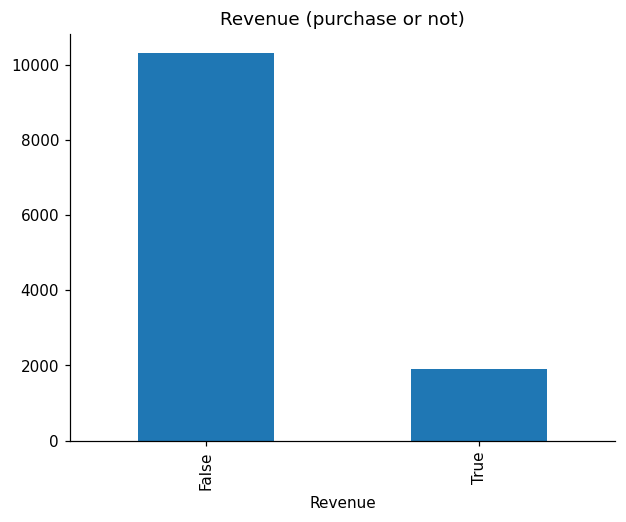

In [15]:
df['Revenue'].value_counts().plot(kind='bar')
plt.title('Revenue (purchase or not)')
plt.show()

The target is well defined but imbalanced (only ~15% purchases), so accuracy alone is not a good metric. We should also look at F1 / precision / recall.

In [16]:
df.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000
mean,2.338878,81.646331,0.508726,34.825454,32.045637,1206.982457,0.020370,0.041466,5.949574,0.061942,2.124211,2.357804,3.153298,4.073904
std,3.330436,177.491845,1.275617,141.424807,44.593649,1919.601400,0.045255,0.046163,18.653671,0.199666,0.906823,1.710114,2.402340,4.016654
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,8.000000,193.000000,0.000000,0.014231,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,9.000000,0.000000,0.000000,18.000000,608.942857,0.002899,0.025000,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,94.700000,0.000000,0.000000,38.000000,1477.154762,0.016667,0.048529,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


## Plan for transforming features
- One-hot encode the categorical features (Month, VisitorType, OperatingSystems, Browser, Region, TrafficType)
- Weekend and Revenue: True/False -> 1/0
- Scale the numeric features (some are very skewed, like the durations, maybe log transform)
- Imbalance: try class weights or SMOTE
- Train/test split with stratify so both sets have the same % of purchases

In [21]:
# quick test of one-hot encoding
df_encoded = pd.get_dummies(df, columns=['Month', 'VisitorType', 'OperatingSystems', 'Browser', 'Region', 'TrafficType'])
df_encoded.shape

(12205, 75)

After one-hot encoding there are more columns but it's still manageable.